In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error
import warnings
warnings.filterwarnings("ignore")

# Зареждане
df = pd.read_csv(
    "data/traffic_aggregated.csv",
    parse_dates=["datetime"]
)

# Feature Engineering
df["hour"]          = df["datetime"].dt.hour
df["dow"]           = df["datetime"].dt.dayofweek
df["month"]         = df["datetime"].dt.month
df["direction_enc"] = (df["direction"] == "Център").astype(int)
df["hour_sin"]      = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"]      = np.cos(2 * np.pi * df["hour"] / 24)
df["dow_sin"]       = np.sin(2 * np.pi * df["dow"] / 7)
df["dow_cos"]       = np.cos(2 * np.pi * df["dow"] / 7)
df["month_sin"]     = np.sin(2 * np.pi * df["month"] / 12)
df["month_cos"]     = np.cos(2 * np.pi * df["month"] / 12)

feature_cols = ["hour_sin", "hour_cos", "dow_sin", "dow_cos",
                "month_sin", "month_cos", "direction_enc"]

print(f"Редове  : {len(df):,}")
print(f"Колони  : {list(df.columns)}")
print(f"Features: {feature_cols}")

Редове  : 52,608
Колони  : ['datetime', 'direction', 'volume', 'avg_speed', 'hour', 'dow', 'month', 'direction_enc', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos']
Features: ['hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'direction_enc']


In [6]:
print("=" * 60)
print("RANDOM FOREST — HYPERPARAMETER TUNING")
print("=" * 60)

# Тренировъчни данни
train_data = df[df["volume"].notna()].copy().reset_index(drop=True)
X = train_data[feature_cols].values
y = train_data["volume"].values

print(f"Тренировъчни редове: {len(train_data):,}")

# TimeSeriesSplit
tscv = TimeSeriesSplit(n_splits=5)

# Параметри за тестване
param_grid = [
    {"n_estimators": 50,  "max_depth": 5},
    {"n_estimators": 50,  "max_depth": 10},
    {"n_estimators": 50,  "max_depth": None},
    {"n_estimators": 100, "max_depth": 5},
    {"n_estimators": 100, "max_depth": 10},
    {"n_estimators": 100, "max_depth": None},
    {"n_estimators": 200, "max_depth": 5},
    {"n_estimators": 200, "max_depth": 10},
    {"n_estimators": 200, "max_depth": None},
]

tuning_results = []

for params in param_grid:
    mae_scores  = []
    rmse_scores = []

    for train_idx, val_idx in tscv.split(X):
        X_train, X_val = X[train_idx], X[val_idx]
        y_train, y_val = y[train_idx], y[val_idx]

        rf = RandomForestRegressor(
            n_estimators = params["n_estimators"],
            max_depth    = params["max_depth"],
            random_state = 42,
            n_jobs       = -1
        )
        rf.fit(X_train, y_train)
        y_pred = rf.predict(X_val)

        mae_scores.append(mean_absolute_error(y_val, y_pred))
        rmse_scores.append(np.sqrt(mean_squared_error(y_val, y_pred)))

    result = {
        "n_estimators": params["n_estimators"],
        "max_depth"   : str(params["max_depth"]),
        "MAE_mean"    : round(np.mean(mae_scores), 2),
        "MAE_std"     : round(np.std(mae_scores), 2),
        "RMSE_mean"   : round(np.mean(rmse_scores), 2),
        "RMSE_std"    : round(np.std(rmse_scores), 2)
    }
    tuning_results.append(result)
    print(f"  n_est={params['n_estimators']:>3}, max_depth={str(params['max_depth']):>5}: "
          f"MAE={np.mean(mae_scores):.2f} ± {np.std(mae_scores):.2f}, "
          f"RMSE={np.mean(rmse_scores):.2f} ± {np.std(rmse_scores):.2f}")

tuning_df = pd.DataFrame(tuning_results)
best_idx  = tuning_df["MAE_mean"].idxmin()
best_params = tuning_results[best_idx]
print(f"\nОптимални параметри:")
print(f"  n_estimators = {best_params['n_estimators']}")
print(f"  max_depth    = {best_params['max_depth']}")
print(f"  MAE          = {best_params['MAE_mean']}")
print(f"  RMSE         = {best_params['RMSE_mean']}")

RANDOM FOREST — HYPERPARAMETER TUNING
Тренировъчни редове: 35,983
  n_est= 50, max_depth=    5: MAE=219.40 ± 17.32, RMSE=294.71 ± 23.20
  n_est= 50, max_depth=   10: MAE=214.85 ± 16.42, RMSE=300.11 ± 21.99
  n_est= 50, max_depth= None: MAE=215.42 ± 16.45, RMSE=303.44 ± 21.47
  n_est=100, max_depth=    5: MAE=219.07 ± 17.17, RMSE=294.31 ± 22.95
  n_est=100, max_depth=   10: MAE=214.54 ± 16.32, RMSE=299.52 ± 21.79
  n_est=100, max_depth= None: MAE=215.19 ± 16.42, RMSE=302.99 ± 21.39
  n_est=200, max_depth=    5: MAE=218.98 ± 17.10, RMSE=294.11 ± 22.80
  n_est=200, max_depth=   10: MAE=214.43 ± 16.35, RMSE=299.43 ± 21.85
  n_est=200, max_depth= None: MAE=215.09 ± 16.44, RMSE=302.84 ± 21.36

Оптимални параметри:
  n_estimators = 200
  max_depth    = 10
  MAE          = 214.43
  RMSE         = 299.43


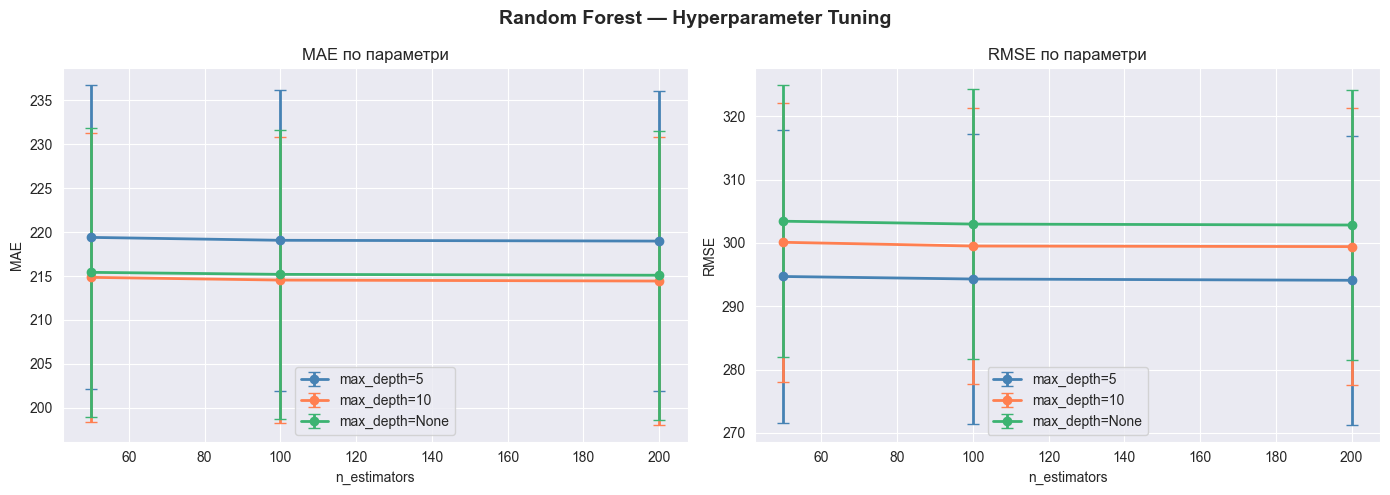

RANDOM FOREST ИМПУТАЦИЯ — ТЕСТОВИ ПЕРИОДИ
  short_1     : MAE= 232.60, RMSE= 278.02
  short_2     : MAE=  40.05, RMSE=  58.24
  short_3     : MAE=  38.51, RMSE=  50.75
  medium_1    : MAE= 232.24, RMSE= 280.36
  medium_2    : MAE=  68.97, RMSE=  92.41
  medium_3    : MAE=  42.52, RMSE=  54.83
  long_1      : MAE= 276.71, RMSE= 333.93
  long_2      : MAE=  59.56, RMSE=  85.80
  long_3      : MAE=  76.89, RMSE= 113.50

Средно по категория:
             MAE    RMSE
category                
long      137.72  177.74
medium    114.58  142.53
short     103.72  129.00


In [7]:
# Визуализация на tuning
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Random Forest — Hyperparameter Tuning", fontsize=14, fontweight="bold")

depths    = ["5", "10", "None"]
colors    = ["steelblue", "coral", "mediumseagreen"]
n_est_vals = [50, 100, 200]

for depth, color in zip(depths, colors):
    subset = tuning_df[tuning_df["max_depth"] == depth]
    ax1.errorbar(subset["n_estimators"], subset["MAE_mean"],
                 yerr=subset["MAE_std"], marker="o", linewidth=2,
                 color=color, capsize=4, label=f"max_depth={depth}")
    ax2.errorbar(subset["n_estimators"], subset["RMSE_mean"],
                 yerr=subset["RMSE_std"], marker="o", linewidth=2,
                 color=color, capsize=4, label=f"max_depth={depth}")

ax1.set_title("MAE по параметри")
ax1.set_xlabel("n_estimators")
ax1.set_ylabel("MAE")
ax1.legend()

ax2.set_title("RMSE по параметри")
ax2.set_xlabel("n_estimators")
ax2.set_ylabel("RMSE")
ax2.legend()

plt.tight_layout()
plt.savefig("rf_tuning.png", dpi=150, bbox_inches="tight")
plt.show()

# Тестови периоди
print("=" * 60)
print("RANDOM FOREST ИМПУТАЦИЯ — ТЕСТОВИ ПЕРИОДИ")
print("=" * 60)

def evaluate(y_true, y_pred, period_name):
    mask   = ~np.isnan(y_true) & ~np.isnan(y_pred)
    y_true = y_true[mask]
    y_pred = y_pred[mask]
    mae    = mean_absolute_error(y_true, y_pred)
    rmse   = np.sqrt(mean_squared_error(y_true, y_pred))
    return {"period": period_name, "MAE": round(mae, 2), "RMSE": round(rmse, 2)}

def create_test_set(df, start, end):
    mask   = (df["datetime"] >= start) & (df["datetime"] <= end)
    subset = df[mask].copy().reset_index(drop=True)
    subset["volume_true"] = subset["volume"]
    subset["volume"]      = np.nan
    return subset

test_periods = {
    "short_1" : ("2023-06-05", "2023-06-07"),
    "short_2" : ("2023-11-05", "2023-11-07"),
    "short_3" : ("2023-12-05", "2023-12-07"),
    "medium_1": ("2023-06-05", "2023-06-18"),
    "medium_2": ("2023-11-05", "2023-11-18"),
    "medium_3": ("2023-12-05", "2023-12-18"),
    "long_1"  : ("2023-06-01", "2023-06-30"),
    "long_2"  : ("2023-11-01", "2023-11-30"),
    "long_3"  : ("2023-12-01", "2023-12-31"),
}

def rf_imputation(df, test_df, start, end, n_estimators=200, max_depth=10):
    train = df[
        ((df["datetime"] < start) | (df["datetime"] > end)) &
        (df["volume"].notna())
    ].copy()

    X_train = train[feature_cols].values
    y_train = train["volume"].values

    rf = RandomForestRegressor(
        n_estimators = n_estimators,
        max_depth    = max_depth,
        random_state = 42,
        n_jobs       = -1
    )
    rf.fit(X_train, y_train)

    result = test_df.copy()
    X_test = result[feature_cols].values
    result["volume_imputed"] = rf.predict(X_test).round(2)

    return result, rf

results_rf = []

for name, (start, end) in test_periods.items():
    test          = create_test_set(df, start, end)
    imputed, model = rf_imputation(df, test, start, end)
    score         = evaluate(
        imputed["volume_true"].values,
        imputed["volume_imputed"].values,
        name
    )
    score["category"] = name.split("_")[0]
    results_rf.append(score)
    print(f"  {name:<12}: MAE={score['MAE']:>7.2f}, RMSE={score['RMSE']:>7.2f}")

results_rf_df = pd.DataFrame(results_rf)
print(f"\nСредно по категория:")
print(results_rf_df.groupby("category")[["MAE","RMSE"]]
      .mean().round(2).to_string())

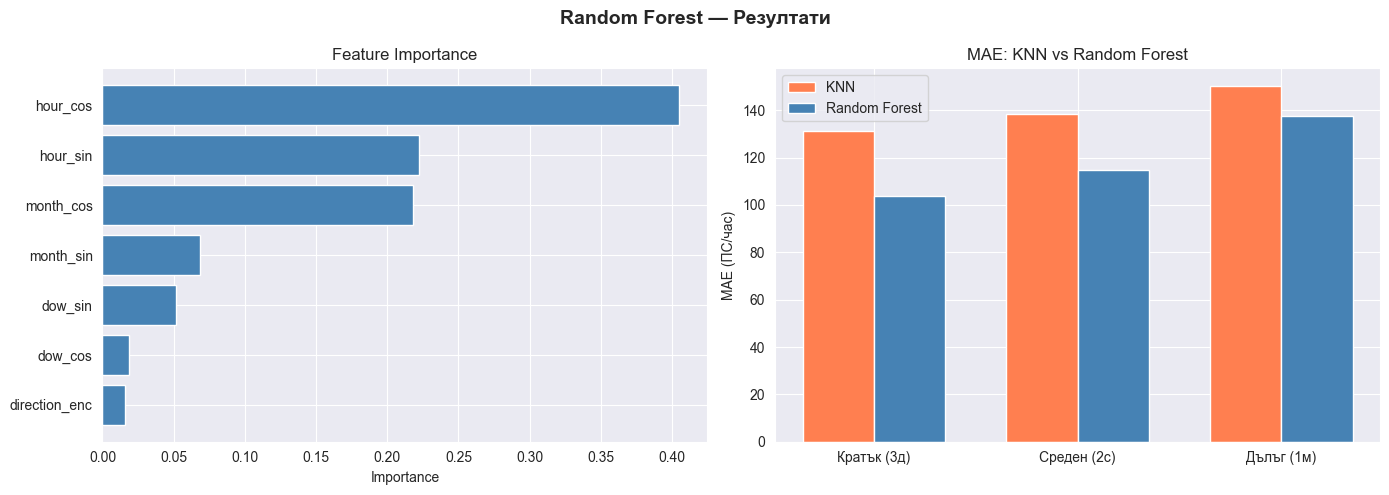

Запазено в data/results_rf.csv


In [8]:
# Зареждане на KNN резултати
results_knn_df = pd.read_csv("data/results_knn.csv")

# Feature importance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Random Forest — Резултати", fontsize=14, fontweight="bold")

# Feature importance от последния модел
_, last_model = rf_imputation(df,
                               create_test_set(df, "2023-11-01", "2023-11-30"),
                               "2023-11-01", "2023-11-30")

importance_df = pd.DataFrame({
    "feature"   : feature_cols,
    "importance": last_model.feature_importances_
}).sort_values("importance", ascending=True)

axes[0].barh(importance_df["feature"], importance_df["importance"],
             color="steelblue", edgecolor="white")
axes[0].set_title("Feature Importance")
axes[0].set_xlabel("Importance")

# Сравнение MAE по категория — зареждаме от CSV
categories = ["short", "medium", "long"]
x          = np.arange(len(categories))
width      = 0.35

knn_mae = [results_knn_df[results_knn_df["category"]==c]["MAE"].mean() for c in categories]
rf_mae  = [results_rf_df[results_rf_df["category"]==c]["MAE"].mean()  for c in categories]

axes[1].bar(x - width/2, knn_mae, width, label="KNN",           color="coral",     edgecolor="white")
axes[1].bar(x + width/2, rf_mae,  width, label="Random Forest", color="steelblue", edgecolor="white")
axes[1].set_title("MAE: KNN vs Random Forest")
axes[1].set_xticks(x)
axes[1].set_xticklabels(["Кратък (3д)", "Среден (2с)", "Дълъг (1м)"])
axes[1].set_ylabel("MAE (ПС/час)")
axes[1].legend()

plt.tight_layout()
plt.savefig("rf_results.png", dpi=150, bbox_inches="tight")
plt.show()

# Запазване на RF резултатите
results_rf_df.to_csv("data/results_rf.csv", index=False)
print("Запазено в data/results_rf.csv")